## Frecuencia respiratoria desde PPG de dedo en sujetos sanos despiertos (CASE) — estudio final
**Pregunta:** ¿Sirven los métodos de detección de RR desde la PPG en sujetos sanos y despiertos,
para detectar activación emocional como la RR de una banda torácica?

**Protocolo (fijado antes de ver los resultados de prueba):**
- Ventanas de 30 s (paso 10 s; análisis secundario con 60 s cambiando `VENTANA` en c-1) dentro de un vídeo emocional, sin artefacto en la PPG y con referencia de banda
  fiable (conteo de respiraciones y FFT de la banda coinciden ≤ 2 rpm).
- División por participantes de los notebooks 09 y 12: **15 de desarrollo / 15 de prueba** (semilla 2026).
- Se **elige** el método con desarrollo (menor MAE mediano por participante entre los que estiman ≥ 80 % de las
  ventanas) y se **informa** en prueba. Todos los métodos de reglas tienen parámetros fijados de antemano.
- Comparaciones pareadas por participante (Wilcoxon) en prueba, sobre las ventanas que ambos métodos estiman.
- Utilidad: clasificación de activación (vídeos divertido/miedo frente a aburrido/relajante) dejando un
  participante fuera, con HRV de la PPG ± RR de la banda o de la PPG.

**Métodos:**
| | Método | Tipo |
|---|---|---|
| A | FFT de la RIIV, máximo global 6–35 rpm (config congelada BIDMC/CapnoBase) | espectral estándar |
| SF | Tipo Smart Fusion (Karlen et al., 2013): FFT de RIIV, RIAV, RIFV; media si DE ≤ 4 rpm, si no abstención | espectral estándar |
| B | Mediana de los máximos de las 3 modulaciones, banda ≥ 10 rpm (notebook 09) | espectral con banda ajustada |
| S | FFT con corrección del fondo 1/f: pico de mayor prominencia sobre el fondo ajustado | espectral propuesto |
| S-AR | Igual que S con espectro autorregresivo (Burg, orden 10) | espectral propuesto |
| D | Conteo de respiraciones en el tiempo, pasa-alto 0.17 Hz | temporal |
| Da | Conteo con pasa-alto adaptativo 0.6 × RR(S) | temporal propuesto |
| F | Fusión S + Da: media si coinciden ± 2 rpm, si no abstención | fusión propuesta |
| F-t | F con fusión temporal: mediana de las últimas 3 estimaciones disponibles del mismo vídeo | fusión propuesta |
| CNN | CNN-LSTM sobre PPG cruda (notebook 12; validación cruzada en desarrollo, entrenada con desarrollo) | aprendizaje profundo |

In [ ]:
# c-0 — Preparación: en Colab clona el código y descomprime los datos; en local no hace nada
import os, sys, shutil, subprocess

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE = '/content/drive/MyDrive/respiratory-rate-ppg'
    LOCAL = '/content/respiratory-rate-ppg'
    if not os.path.exists(LOCAL):
        subprocess.run(["git","clone","-q","https://github.com/carlosgmontoya/respiratory-rate-ppg.git",LOCAL],check=True)
    else:
        subprocess.run(["git","-C",LOCAL,"pull","-q"],check=True)
    if not os.path.exists(LOCAL + '/data/CASE'):
        subprocess.run(["unzip", "-q", f"{DRIVE}/data/CASE.zip", "-d", f"{LOCAL}/data/"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wfdb", "xgboost"], check=True)
    os.chdir(LOCAL + '/notebooks')

print("Entorno:", "Colab" if EN_COLAB else "local", "| carpeta:", os.getcwd())
print("CASE encontrado:", os.path.exists('../data/CASE/data/interpolated/physiological'))

Entorno: local | carpeta: c:\Users\Usuario\Documents\respiratory-rate-ppg\notebooks
CASE encontrado: True


In [11]:
# c-1 — Imports, configuración y rutas
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, decimate, filtfilt, find_peaks, resample_poly
from scipy.stats import wilcoxon
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(BASE_DIR / "notebooks"))
sys.path.insert(0, str(Path.cwd()))
import rr_generalizable as rg

VENTANA = 30                                  # s. Análisis principal: 30. Análisis secundario: cambia a 60.
rg.VENTANA_S, rg.N = VENTANA, VENTANA * rg.FS  # el módulo usa estos valores en cada ventana

OUT = BASE_DIR / "results"
RES = OUT if VENTANA == 30 else OUT / f"ventana_{VENTANA}s"   # los resultados de 60 s no pisan los de 30 s
RES.mkdir(exist_ok=True)
CFG = json.loads((OUT / "config_congelada.json").read_text())
SPLIT = json.loads((OUT / "config_case_correccion.json").read_text())
CASE_DEV = set(SPLIT["case_desarrollo"])
P = {**rg.PARAMS, "rpm_min": CFG["rpm_min"], "rpm_max": CFG["rpm_max"], "lp_riiv_hz": CFG["lp_fft_hz"],
     "lp_art_hz": CFG["lp_art_hz"], "umbral_art": CFG["umbral_art"]}
VENTANA_S, PASO_S, FS = rg.VENTANA_S, rg.PASO_S, rg.FS
CASE_DIR = BASE_DIR / "data" / "CASE" / "data" / "interpolated" / "physiological"
ARCHIVOS = sorted(CASE_DIR.glob("sub_*.csv"), key=lambda p: int(p.stem.split("_")[1]))
ACTIVACION = {1: 1, 2: 1, 7: 1, 8: 1, 3: 0, 4: 0, 5: 0, 6: 0}
COB_MIN = 80                                  # % mínimo de ventanas estimadas para poder ser elegido
pd.set_option("display.width", 250)
warnings.filterwarnings("ignore", category=RuntimeWarning)   # correlaciones de sujetos sin variación
print(f"{len(ARCHIVOS)} participantes | desarrollo: {len(CASE_DEV)} | ventana {VENTANA} s, paso {PASO_S} s | resultados en {RES}")

30 participantes | desarrollo: 15 | ventana 30 s, paso 10 s | resultados en c:\Users\Usuario\Documents\respiratory-rate-ppg\results


In [14]:
# c-2 — Funciones auxiliares (referencia, métodos espectrales estándar, HRV)
def rr_ref(m, t0, t1, min_marcas=3):
    m = m[(m >= t0) & (m < t1)]
    return np.nan if len(m) < min_marcas else 60.0 / np.median(np.diff(m))

def marcas_banda(rsp, fs=1000):
    x = decimate(decimate(rsp, 10, zero_phase=True), 4, zero_phase=True)
    f = fs / 40
    b, a = butter(2, [0.05, 1.0], btype="band", fs=f)
    x = filtfilt(b, a, x)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    pk, _ = find_peaks(x, distance=int(f), prominence=0.25 * iqr)
    return pk / f

def maximo(x, lo, hi=P["rpm_max"]):
    f, Pw = rg.espectro(x, rg.FS_M, 1024)
    b = (f >= lo) & (f <= hi)
    return f[b][np.argmax(Pw[b])]

def hrv(t, ibi, t0):
    m = (t >= t0) & (t < t0 + VENTANA_S)
    if m.sum() < 15:
        return np.nan, np.nan, np.nan
    tw, iw = t[m], ibi[m]
    consec = np.abs(np.diff(tw) - iw[1:]) < 0.02
    d = np.diff(iw)[consec]
    rmssd = np.log(1000 * np.sqrt(np.mean(d ** 2))) if consec.sum() >= 10 else np.nan
    return 60 / iw.mean(), rmssd, np.log(1000 * iw.std())

In [15]:
# c-3 — Ventanas y estimaciones de todos los métodos (tarda ~10–15 min)
filas, t_ini = [], time.time()
for p in ARCHIVOS:
    d = pd.read_csv(p, usecols=["bvp", "rsp", "video"])
    vid = d["video"].to_numpy(int)
    rsp = d["rsp"].to_numpy(float)
    marcas = marcas_banda(rsp)
    rsp5 = decimate(decimate(resample_poly(rsp, FS, 1000), 5, zero_phase=True), 5, zero_phase=True)
    est = rg.Estimador(d["bvp"].to_numpy(float), 1000, P)
    for t0 in est.inicios():
        v = vid[int(t0 * 1000):int((t0 + VENTANA_S) * 1000)]
        if len(v) == 0 or v.min() != v.max() or v[0] not in ACTIVACION:
            continue
        r = rr_ref(marcas, t0, t0 + VENTANA_S)
        seg = rsp5[int(t0 * 5):int((t0 + VENTANA_S) * 5)]
        if not np.isfinite(r) or not P["rpm_min"] <= r <= P["rpm_max"] or len(seg) < VENTANA_S * 5:
            continue
        f, Pw = rg.espectro(seg, 5, 2048)
        bnd = (f >= P["rpm_min"]) & (f <= P["rpm_max"])
        if abs(r - f[bnd][np.argmax(Pw[bnd])]) > 2:
            continue                                      # referencia no fiable
        w = est.ventana(t0)
        series = [rg.serie_4hz(est.t, s, t0) for s in est.mods.values()]
        ok = [s for s in series if s is not None]
        sf = [maximo(s, P["rpm_min"]) for s in ok]
        fc, rmssd, sdnn = hrv(est.t, est.mods["RIFV"], t0)
        filas.append({"Participante": p.stem, "Conjunto": "desarrollo" if p.stem in CASE_DEV else "prueba",
                      "Inicio (s)": t0, "Vídeo": int(v[0]), "Activación": ACTIVACION[int(v[0])],
                      "RR banda": r, "Artefacto": w["Artefacto"],
                      "A": w["A"],
                      "SF": np.mean(sf) if len(sf) == 3 and np.std(sf) <= 4 else np.nan,
                      "B": rg.mediana3([maximo(s, 10) for s in ok] + [np.nan] * (3 - len(ok))),
                      "S": w["S"], "S-AR": w["S-AR"], "D": w["D"], "Da": w["Da"], "F": w["F"],
                      "FC": fc, "lnRMSSD": rmssd, "lnSDNN": sdnn})
    print(p.stem, end=" ")
R = pd.DataFrame(filas).sort_values(["Participante", "Inicio (s)"]).reset_index(drop=True)

# Fusión temporal: mediana de las últimas 3 estimaciones F disponibles dentro del mismo vídeo (causal)
bloque = ((R["Participante"] != R["Participante"].shift()) | (R["Vídeo"] != R["Vídeo"].shift())).cumsum()
R["F-t"] = R.groupby(bloque)["F"].transform(lambda s: s.rolling(3, min_periods=1).median())
R.loc[R["F"].isna(), "F-t"] = np.nan                       # se mantiene la abstención de la ventana actual

# CNN-LSTM del notebook 12 (si existe su archivo de predicciones; solo con ventanas de 30 s, como se entrenó)
f12 = OUT / "case_rr_mejor_ventanas.csv"
if VENTANA == 30 and f12.exists() and "G: CNN-LSTM (PPG cruda)" in pd.read_csv(f12, nrows=0).columns:
    c12 = pd.read_csv(f12, usecols=["Participante", "Inicio (s)", "G: CNN-LSTM (PPG cruda)"])
    R = R.merge(c12.rename(columns={"G: CNN-LSTM (PPG cruda)": "CNN"}), on=["Participante", "Inicio (s)"], how="left")
METODOS = ["A", "SF", "B", "S", "S-AR", "D", "Da", "F", "F-t"] + (["CNN"] if "CNN" in R else [])
R.to_csv(RES / "case_final_ventanas.csv", index=False)
V = R[~R["Artefacto"]].copy()
print(f"\n{len(R)} ventanas con referencia fiable; {len(V)} sin artefacto ({time.time() - t_ini:.0f} s)")
print(V.groupby("Conjunto")["Participante"].agg(["nunique", "size"]))

sub_1 sub_2 sub_3 sub_4 sub_5 sub_6 sub_7 sub_8 sub_9 sub_10 sub_11 sub_12 sub_13 sub_14 sub_15 sub_16 sub_17 sub_18 sub_19 sub_20 sub_21 sub_22 sub_23 sub_24 sub_25 sub_26 sub_27 sub_28 sub_29 sub_30 
2561 ventanas con referencia fiable; 2330 sin artefacto (59 s)
            nunique  size
Conjunto                 
desarrollo       15  1184
prueba           15  1146


In [5]:
# c-4 — Métricas
def metricas(g, col):
    ok = g[col].notna()
    if ok.sum() == 0:
        return {"Cobertura %": 0.0}
    h = g[ok]
    err = h[col] - h["RR banda"]
    e = err.abs()
    r = h.groupby("Participante").apply(lambda s: s[col].corr(s["RR banda"]) if s[col].std() > 0 else np.nan)
    dl = h.groupby(["Participante", "Activación"])[[col, "RR banda"]].mean().unstack()
    if (col, 1) in dl and (col, 0) in dl:
        dm, dr = dl[(col, 1)] - dl[(col, 0)], dl[("RR banda", 1)] - dl[("RR banda", 0)]
    else:
        dm = dr = pd.Series(dtype=float)
    return {"MAE mediano": e.groupby(h["Participante"]).mean().median(), "MAE medio": e.mean(),
            "RMSE": np.sqrt((err ** 2).mean()), "Sesgo": err.mean(),
            "LdA inf": err.mean() - 1.96 * err.std(), "LdA sup": err.mean() + 1.96 * err.std(),
            "% ≤ 2 rpm": 100 * (e <= 2).mean(), "Cobertura %": 100 * ok.mean(),
            "r dentro de sujeto": r.median(), "Δ método": dm.median(), "Δ banda": dr.median(),
            "r de los Δ": dm.corr(dr)}

TAB = {c: pd.DataFrame({m: metricas(V[V["Conjunto"] == c] if c != "todos" else V, m) for m in METODOS}).T
       for c in ["desarrollo", "prueba", "todos"]}
pd.concat(TAB, names=["Conjunto", "Método"]).to_csv(RES / "case_final_resumen.csv")
print("=== DESARROLLO (para elegir) ===")
print(TAB["desarrollo"].sort_values("MAE mediano").round(2).to_string())
cand = TAB["desarrollo"][(TAB["desarrollo"]["Cobertura %"] >= COB_MIN) & TAB["desarrollo"]["MAE mediano"].notna()]
ELEGIDO = cand["MAE mediano"].idxmin()
print(f"\nMétodo elegido en desarrollo: {ELEGIDO}")

=== DESARROLLO (para elegir) ===
      MAE mediano  MAE medio   RMSE  Sesgo  LdA inf  LdA sup  % ≤ 2 rpm  Cobertura %  r dentro de sujeto  Δ método  Δ banda  r de los Δ
F-t          1.37       1.46   2.63  -0.25    -5.39     4.89      80.27        76.18                0.30      0.33     1.05        0.57
F            1.39       1.37   2.71  -0.22    -5.52     5.08      84.48        76.18                0.32      0.60     1.05        0.61
D            1.62       1.70   2.56  -0.41    -5.36     4.54      72.55       100.00                0.41      0.66     1.20        0.55
Da           2.07       2.00   3.38  -0.04    -6.67     6.60      73.23       100.00                0.19      0.77     1.20        0.62
S            2.24       2.33   4.30   0.15    -8.26     8.57      72.55       100.00                0.19      0.88     1.20        0.56
CNN          2.65       3.42   4.32  -0.04    -8.50     8.43      36.06       100.00                0.03     -0.06     1.20        0.35
B            2.

In [6]:
# c-5 — PRUEBA: resultados y comparaciones pareadas con el método elegido
print("=== PRUEBA (evaluación honesta) ===")
print(TAB["prueba"].sort_values("MAE mediano").round(2).to_string())
T = V[V["Conjunto"] == "prueba"]
filas = []
for m in METODOS:
    if m == ELEGIDO:
        continue
    comun = T[T[ELEGIDO].notna() & T[m].notna()]
    ea = (comun[ELEGIDO] - comun["RR banda"]).abs().groupby(comun["Participante"]).mean()
    eb = (comun[m] - comun["RR banda"]).abs().groupby(comun["Participante"]).mean()
    dlt = (ea - eb).dropna()
    filas.append({"Comparación": f"{ELEGIDO} vs {m}", "Participantes": len(dlt), "Ventanas comunes": len(comun),
                  f"MAE {ELEGIDO}": ea.median(), f"MAE otro": eb.median(), "Δ mediana": dlt.median(),
                  "Wilcoxon p": wilcoxon(dlt).pvalue if (dlt != 0).any() and len(dlt) > 1 else np.nan})
CMP = pd.DataFrame(filas)
CMP.to_csv(RES / "case_final_comparaciones.csv", index=False)
print("\nComparaciones pareadas por participante (prueba, ventanas comunes; Δ < 0 = el elegido es mejor):")
print(CMP.round(3).to_string(index=False))

=== PRUEBA (evaluación honesta) ===
      MAE mediano  MAE medio   RMSE  Sesgo  LdA inf  LdA sup  % ≤ 2 rpm  Cobertura %  r dentro de sujeto  Δ método  Δ banda  r de los Δ
F            0.62       0.92   2.04   0.00    -3.99     4.00      93.01        87.43                0.88      1.27     1.55        0.85
F-t          0.85       0.96   1.77  -0.04    -3.51     3.44      90.02        87.43                0.77      0.88     1.55        0.81
D            1.01       1.29   2.06   0.25    -3.77     4.26      81.94       100.00                0.68      0.94     1.30        0.72
Da           1.08       1.29   2.52   0.16    -4.77     5.09      85.15        99.91                0.70      0.97     1.31        0.80
S            1.24       1.54   3.29   0.24    -6.20     6.68      84.38       100.00                0.51      1.14     1.30        0.62
CNN          1.77       2.64   3.55   1.59    -4.63     7.81      51.40       100.00                0.18     -0.10     1.30        0.31
B           

 Tolerancia (rpm)  MAE mediano  % ≤ 2 rpm  Cobertura %  r dentro de sujeto
              0.5         0.69      91.78        34.98                0.83
              1.0         0.84      91.03        60.77                0.72
              1.5         0.88      89.91        73.99                0.68
              2.0         0.95      88.97        81.72                0.73
              3.0         1.03      86.55        89.36                0.70
              4.0         1.11      84.49        93.26                0.62
              6.0         1.30      81.36        97.85                0.50
              inf         1.39      80.03        99.96                0.44


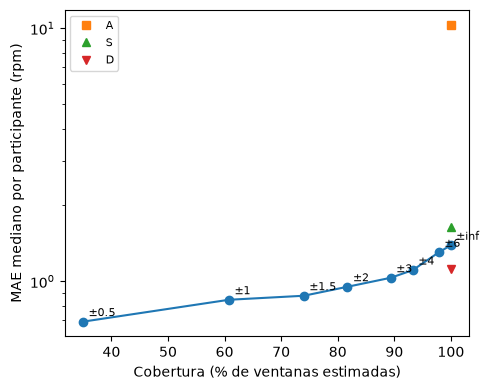

In [7]:
# c-6 — Compromiso exactitud–cobertura de la fusión (todos los participantes)
filas = []
for tol in [0.5, 1, 1.5, 2, 3, 4, 6, np.inf]:
    col = f"F tol {tol}"
    V[col] = rg.fusion(V["S"], V["Da"], tol) if np.isfinite(tol) else (V["S"] + V["Da"]) / 2
    m = metricas(V, col)
    filas.append({"Tolerancia (rpm)": tol, "MAE mediano": m.get("MAE mediano"), "% ≤ 2 rpm": m.get("% ≤ 2 rpm"),
                  "Cobertura %": m["Cobertura %"], "r dentro de sujeto": m.get("r dentro de sujeto")})
CC = pd.DataFrame(filas)
print(CC.round(2).to_string(index=False))
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(CC["Cobertura %"], CC["MAE mediano"], "o-")
for _, r_ in CC.iterrows():
    ax.annotate(f"±{r_['Tolerancia (rpm)']:g}", (r_["Cobertura %"], r_["MAE mediano"]), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
for m, mk in [("A", "s"), ("S", "^"), ("D", "v")]:
    mm = metricas(V, m)
    ax.plot(mm["Cobertura %"], mm["MAE mediano"], mk, label=m)
ax.set_xlabel("Cobertura (% de ventanas estimadas)")
ax.set_ylabel("MAE mediano por participante (rpm)")
ax.set_yscale("log")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RES / "case_final_cobertura.png", dpi=300)
plt.show()

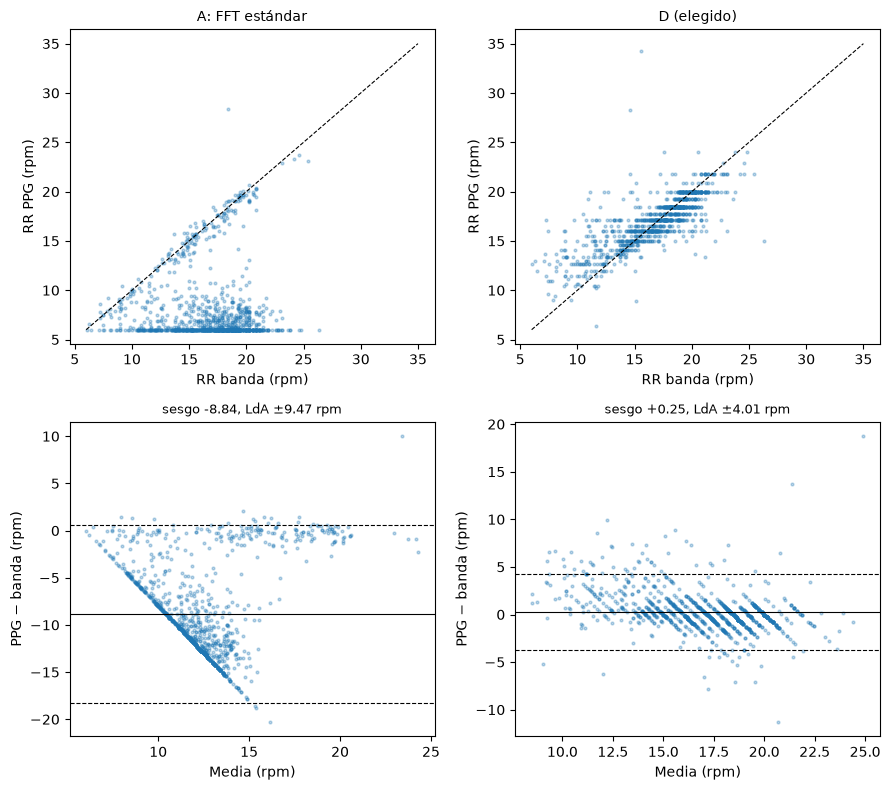

In [8]:
# c-7 — Figuras de acuerdo en prueba: FFT estándar frente al método elegido
fig, axs = plt.subplots(2, 2, figsize=(9, 8))
for j, (nombre, col) in enumerate([("A: FFT estándar", "A"), (f"{ELEGIDO} (elegido)", ELEGIDO)]):
    h = T[T[col].notna()]
    axs[0, j].scatter(h["RR banda"], h[col], s=4, alpha=0.3)
    axs[0, j].plot([6, 35], [6, 35], "k--", lw=0.8)
    axs[0, j].set_xlabel("RR banda (rpm)")
    axs[0, j].set_ylabel("RR PPG (rpm)")
    axs[0, j].set_title(nombre, fontsize=10)
    media, dif = (h[col] + h["RR banda"]) / 2, h[col] - h["RR banda"]
    axs[1, j].scatter(media, dif, s=4, alpha=0.3)
    for y_, ls in [(dif.mean(), "-"), (dif.mean() + 1.96 * dif.std(), "--"), (dif.mean() - 1.96 * dif.std(), "--")]:
        axs[1, j].axhline(y_, c="k", ls=ls, lw=0.8)
    axs[1, j].set_xlabel("Media (rpm)")
    axs[1, j].set_ylabel("PPG − banda (rpm)")
    axs[1, j].set_title(f"sesgo {dif.mean():+.2f}, LdA ±{1.96 * dif.std():.2f} rpm", fontsize=9)
plt.tight_layout()
plt.savefig(RES / "case_final_acuerdo.png", dpi=300)
plt.show()

In [9]:
# c-8 — Utilidad: detección de activación (dejando un participante fuera, todos los participantes)
# Todos los brazos usan las mismas ventanas: aquellas donde el método elegido estima (si se abstiene, la ventana
# se excluye para todos), para que la comparación sea justa.
BRAZOS = {"HRV": ["FC", "lnRMSSD", "lnSDNN"],
          "HRV + RR banda": ["FC", "lnRMSSD", "lnSDNN", "RR banda"],
          f"HRV + RR PPG ({ELEGIDO})": ["FC", "lnRMSSD", "lnSDNN", ELEGIDO],
          "HRV + RR PPG (A, FFT estándar)": ["FC", "lnRMSSD", "lnSDNN", "A"],
          "RR banda sola": ["RR banda"],
          f"RR PPG sola ({ELEGIDO})": [ELEGIDO]}
cols = sorted({c for cs in BRAZOS.values() for c in cs})
C = V.dropna(subset=cols).copy()
C[cols] = C.groupby("Participante")[cols].transform(lambda c: (c - c.mean()) / (c.std() + 1e-9))
y, part = C["Activación"].to_numpy(), C["Participante"].to_numpy()
print(f"Ventanas para clasificar: {len(C)} ({C['Participante'].nunique()} participantes)")
AUC = []
for brazo, cs in BRAZOS.items():
    X = C[cs].to_numpy()
    for s in np.unique(part):
        te = part == s
        if len(np.unique(y[te])) < 2:
            continue
        clf = LogisticRegression(max_iter=1000).fit(X[~te], y[~te])
        AUC.append({"Brazo": brazo, "Participante": s, "AUC": roc_auc_score(y[te], clf.predict_proba(X[te])[:, 1])})
A_ = pd.DataFrame(AUC)
A_.to_csv(RES / "case_final_auc.csv", index=False)
print(A_.groupby("Brazo", sort=False)["AUC"].agg(["count", "median", "mean"]).round(3).to_string())
W = A_.pivot(index="Participante", columns="Brazo", values="AUC")
for a, b in [("HRV + RR banda", "HRV"), (f"HRV + RR PPG ({ELEGIDO})", "HRV"),
             (f"HRV + RR PPG ({ELEGIDO})", "HRV + RR banda"), (f"HRV + RR PPG ({ELEGIDO})", "HRV + RR PPG (A, FFT estándar)")]:
    dlt = (W[a] - W[b]).dropna()
    p_ = wilcoxon(dlt).pvalue if (dlt != 0).any() and len(dlt) > 1 else np.nan
    print(f"{a}  vs  {b}: Δ AUC mediana {dlt.median():+.3f}, Wilcoxon p = {p_:.3f}")

Ventanas para clasificar: 2327 (30 participantes)
                                count  median   mean
Brazo                                               
HRV                                30   0.615  0.591
HRV + RR banda                     30   0.684  0.671
HRV + RR PPG (D)                   30   0.666  0.624
HRV + RR PPG (A, FFT estándar)     30   0.619  0.589
RR banda sola                      30   0.709  0.675
RR PPG sola (D)                    30   0.620  0.618
HRV + RR banda  vs  HRV: Δ AUC mediana +0.092, Wilcoxon p = 0.008
HRV + RR PPG (D)  vs  HRV: Δ AUC mediana +0.022, Wilcoxon p = 0.084
HRV + RR PPG (D)  vs  HRV + RR banda: Δ AUC mediana -0.045, Wilcoxon p = 0.026
HRV + RR PPG (D)  vs  HRV + RR PPG (A, FFT estándar): Δ AUC mediana +0.021, Wilcoxon p = 0.088


In [10]:
# c-9 — Configuración final para el wearable
(RES / "config_case_final.json").write_text(json.dumps(
    {"metodo_elegido": ELEGIDO, "params": {**P, "fondo_rpm": list(P["fondo_rpm"])},
     "criterio": f"menor MAE mediano en desarrollo con cobertura >= {COB_MIN} %",
     "ventana_s": VENTANA, "paso_s": PASO_S, "case_desarrollo": sorted(CASE_DEV)}, indent=2, default=float))
print(f"Guardado: {RES / 'config_case_final.json'}")

Guardado: c:\Users\Usuario\Documents\respiratory-rate-ppg\results\config_case_final.json


In [16]:
# c-12 — Robustez de la detección de activación: 3 clasificadores × 2 etiquetas (vídeo y joystick)
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
try:
    from xgboost import XGBClassifier
    GB_NOMBRE, crear_gb = "XGBoost", lambda: XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                                                             subsample=0.8, eval_metric="logloss", verbosity=0)
except ImportError:                       # si xgboost no está instalado se usa el equivalente de scikit-learn
    GB_NOMBRE, crear_gb = "Gradient boosting", lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                                                                    max_depth=3, random_state=0)
MODELOS = {"Regresión logística": lambda: LogisticRegression(max_iter=1000),
           "Random forest": lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=0),
           GB_NOMBRE: crear_gb}
BRAZOS3 = {"HRV": ["FC", "lnRMSSD", "lnSDNN"],
           "HRV + RR banda": ["FC", "lnRMSSD", "lnSDNN", "RR banda"],
           "HRV + RR PPG (D)": ["FC", "lnRMSSD", "lnSDNN", "D"],
           "HRV + RR PPG (A)": ["FC", "lnRMSSD", "lnSDNN", "A"]}

# 1) Arousal del joystick: media en cada ventana (anotaciones de CASE, misma base de tiempo que la fisiología)
ANN_DIR = CASE_DIR.parent / "annotations"
V["Arousal joystick"] = np.nan
if ANN_DIR.exists():
    for p in sorted(V["Participante"].unique()):
        fa = ANN_DIR / f"{p}.csv"
        if not fa.exists():
            continue
        ann = pd.read_csv(fa)
        if not {"jstime", "arousal"} <= set(ann.columns):
            continue
        t_daq0 = pd.read_csv(CASE_DIR / f"{p}.csv", usecols=["daqtime"], nrows=1)["daqtime"].iloc[0]
        js, ar = ann["jstime"].to_numpy(float), ann["arousal"].to_numpy(float)
        for i, t0 in V.loc[V["Participante"] == p, "Inicio (s)"].items():
            m = (js >= t_daq0 + 1000 * t0) & (js < t_daq0 + 1000 * (t0 + VENTANA))
            V.at[i, "Arousal joystick"] = ar[m].mean() if m.any() else np.nan
else:
    print(f"No se encontró {ANN_DIR}: solo se usa la etiqueta del vídeo.")

# 2) Ventanas comunes y etiquetas
cols3 = sorted({c for cs in BRAZOS3.values() for c in cs})
C3 = V.dropna(subset=cols3).copy()
C3[cols3] = C3.groupby("Participante")[cols3].transform(lambda c: (c - c.mean()) / (c.std() + 1e-9))
ETIQ = {"Vídeo": C3["Activación"].astype(int)}
if C3["Arousal joystick"].notna().mean() > 0.9:
    C3 = C3[C3["Arousal joystick"].notna()]
    med = C3.groupby("Participante")["Arousal joystick"].transform("median")
    ETIQ = {"Vídeo": C3["Activación"].astype(int), "Joystick": (C3["Arousal joystick"] > med).astype(int)}
part3 = C3["Participante"].to_numpy()
print(f"Ventana {VENTANA} s | ventanas: {len(C3)} | participantes: {len(np.unique(part3))} | etiquetas: {list(ETIQ)}")

# 3) Dejando un participante fuera
filas = []
for et, y in ETIQ.items():
    y = y.to_numpy()
    for mod, crear in MODELOS.items():
        for brazo, cs in BRAZOS3.items():
            X = C3[cs].to_numpy()
            for s in np.unique(part3):
                te = part3 == s
                if len(np.unique(y[te])) < 2 or len(np.unique(y[~te])) < 2:
                    continue
                pr = crear().fit(X[~te], y[~te]).predict_proba(X[te])[:, 1]
                filas.append({"Etiqueta": et, "Modelo": mod, "Brazo": brazo, "Participante": s,
                              "AUC": roc_auc_score(y[te], pr)})
    print(f"{et} listo")
R3 = pd.DataFrame(filas)
R3.to_csv(RES / "case_robustez_auc.csv", index=False)

# 4) Resumen: AUC mediana y comparaciones pareadas (Wilcoxon por participante)
print("\nAUC mediana por participante:")
print(R3.pivot_table(index=["Etiqueta", "Modelo"], columns="Brazo", values="AUC", aggfunc="median")
      [list(BRAZOS3)].round(3).to_string())
COMP = [("HRV + RR banda", "HRV"), ("HRV + RR PPG (D)", "HRV"), ("HRV + RR PPG (A)", "HRV"),
        ("HRV + RR PPG (D)", "HRV + RR banda"), ("HRV + RR PPG (D)", "HRV + RR PPG (A)")]
filas = []
for (et, mod), g in R3.groupby(["Etiqueta", "Modelo"], sort=False):
    W3 = g.pivot(index="Participante", columns="Brazo", values="AUC")
    for a, b in COMP:
        d = (W3[a] - W3[b]).dropna()
        filas.append({"Etiqueta": et, "Modelo": mod, "Comparación": f"{a} vs {b}", "Δ AUC mediana": d.median(),
                      "p": wilcoxon(d).pvalue if (d != 0).any() and len(d) > 1 else np.nan})
CMP3 = pd.DataFrame(filas)
CMP3.to_csv(RES / "case_robustez_comparaciones.csv", index=False)
print("\nComparaciones pareadas (Δ > 0 = el primero es mejor):")
print(CMP3.pivot_table(index=["Etiqueta", "Modelo"], columns="Comparación", values="Δ AUC mediana").round(3).to_string())
print(CMP3.pivot_table(index=["Etiqueta", "Modelo"], columns="Comparación", values="p").round(3).to_string())

Ventana 30 s | ventanas: 2327 | participantes: 30 | etiquetas: ['Vídeo', 'Joystick']
Vídeo listo
Joystick listo

AUC mediana por participante:
Brazo                           HRV  HRV + RR banda  HRV + RR PPG (D)  HRV + RR PPG (A)
Etiqueta Modelo                                                                        
Joystick Random forest        0.551           0.582             0.548             0.573
         Regresión logística  0.576           0.620             0.561             0.579
         XGBoost              0.513           0.603             0.558             0.553
Vídeo    Random forest        0.584           0.654             0.603             0.578
         Regresión logística  0.615           0.684             0.666             0.619
         XGBoost              0.577           0.674             0.619             0.604

Comparaciones pareadas (Δ > 0 = el primero es mejor):
Comparación                   HRV + RR PPG (A) vs HRV  HRV + RR PPG (D) vs HRV  HRV + RR PPG (D) v

In [12]:
print(CMP3[CMP3["Etiqueta"] == "Joystick"].round(3).to_string(index=False))

Etiqueta              Modelo                          Comparación  Δ AUC mediana     p
Joystick Regresión logística                HRV + RR banda vs HRV          0.049 0.021
Joystick Regresión logística              HRV + RR PPG (D) vs HRV          0.027 0.177
Joystick Regresión logística              HRV + RR PPG (A) vs HRV          0.000 0.845
Joystick Regresión logística   HRV + RR PPG (D) vs HRV + RR banda         -0.047 0.043
Joystick Regresión logística HRV + RR PPG (D) vs HRV + RR PPG (A)          0.021 0.177
Joystick       Random forest                HRV + RR banda vs HRV          0.058 0.002
Joystick       Random forest              HRV + RR PPG (D) vs HRV          0.040 0.002
Joystick       Random forest              HRV + RR PPG (A) vs HRV          0.020 0.011
Joystick       Random forest   HRV + RR PPG (D) vs HRV + RR banda         -0.010 0.309
Joystick       Random forest HRV + RR PPG (D) vs HRV + RR PPG (A)          0.009 0.318
Joystick             XGBoost               

In [13]:
from scipy.stats import false_discovery_control
CMP3["p ajustada (BH)"] = false_discovery_control(CMP3["p"].fillna(1).to_numpy())
print(CMP3.round(3).to_string(index=False))

Etiqueta              Modelo                          Comparación  Δ AUC mediana     p  p ajustada (BH)
   Vídeo Regresión logística                HRV + RR banda vs HRV          0.092 0.008            0.020
   Vídeo Regresión logística              HRV + RR PPG (D) vs HRV          0.022 0.084            0.126
   Vídeo Regresión logística              HRV + RR PPG (A) vs HRV          0.001 0.538            0.556
   Vídeo Regresión logística   HRV + RR PPG (D) vs HRV + RR banda         -0.045 0.026            0.052
   Vídeo Regresión logística HRV + RR PPG (D) vs HRV + RR PPG (A)          0.021 0.088            0.126
   Vídeo       Random forest                HRV + RR banda vs HRV          0.097 0.001            0.003
   Vídeo       Random forest              HRV + RR PPG (D) vs HRV          0.052 0.000            0.001
   Vídeo       Random forest              HRV + RR PPG (A) vs HRV          0.005 0.289            0.334
   Vídeo       Random forest   HRV + RR PPG (D) vs HRV + RR band

In [2]:
# Guardar resultados: en Colab se copian a Drive; en local ya están en results/
if EN_COLAB:
    shutil.copytree(LOCAL + '/results', DRIVE + '/resultados_colab', dirs_exist_ok=True)
    print("Resultados copiados a Drive:", DRIVE + '/resultados_colab')
else:
    print("Resultados en la carpeta results/ local")

Resultados en la carpeta results/ local


In [8]:
# %% [c-14 — Equivalencia / no inferioridad: RR de la PPG (Count) frente a RR de la banda]
# Lee el resultado de c-12 (case_robustez_auc.csv), así que puede ejecutarse sola tras c-1.
# Para cada etiqueta × clasificador: d = AUC(HRV + RR PPG) − AUC(HRV + RR banda) por participante.
#   - No inferioridad (H0: d ≤ −δ): Wilcoxon unilateral sobre d + δ.
#   - Equivalencia TOST (H0: |d| ≥ δ): las dos pruebas unilaterales; p_TOST = max(p_inf, p_sup).
#   - IC 90 % bootstrap por participante de la mediana de d (equivalente gráfico del TOST).
# Márgenes δ en AUC: 0.03, 0.05 y 0.10 (se reportan todos; el margen principal debe justificarse).
import numpy as np, pandas as pd
from scipy.stats import wilcoxon, false_discovery_control

AU = pd.read_csv(RES / "case_robustez_auc.csv")
PPG, BANDA = "HRV + RR PPG (D)", "HRV + RR banda"
MARGENES = [0.03, 0.05, 0.10]
rng = np.random.default_rng(2026)

filas = []
for (et, mod), g in AU.groupby(["Etiqueta", "Modelo"], sort=False):
    W = g.pivot(index="Participante", columns="Brazo", values="AUC")
    d = (W[PPG] - W[BANDA]).dropna().to_numpy()
    boot = np.median(d[rng.integers(0, len(d), (5000, len(d)))], axis=1)
    lo, hi = np.percentile(boot, [5, 95])
    for m in MARGENES:
        p_inf = wilcoxon(d + m, alternative="greater").pvalue      # H0: d ≤ −δ  (no inferioridad)
        p_sup = wilcoxon(d - m, alternative="less").pvalue         # H0: d ≥ +δ
        filas.append({"Etiqueta": et, "Modelo": mod, "n": len(d), "Δ mediana": np.median(d),
                      "IC90 inf": lo, "IC90 sup": hi, "δ": m,
                      "p no inferior": p_inf, "p TOST": max(p_inf, p_sup)})
T = pd.DataFrame(filas)
for col in ["p no inferior", "p TOST"]:                            # BH sobre las 6 configuraciones de cada δ
    T[col + " (BH)"] = T.groupby("δ")[col].transform(lambda p: false_discovery_control(p.to_numpy()))
T["No inferior"] = T["p no inferior (BH)"] < 0.05
T["Equivalente"] = T["p TOST (BH)"] < 0.05
T.to_csv(RES / "case_equivalencia_tost.csv", index=False)

pd.set_option("display.width", 200)
print(f"Ventana {VENTANA} s — Δ = AUC(HRV + RR PPG) − AUC(HRV + RR banda); IC 90 % bootstrap por participante\n")
print(T.groupby(["Etiqueta", "Modelo"], sort=False)[["n", "Δ mediana", "IC90 inf", "IC90 sup"]].first().round(3).to_string())
print("\nResumen por margen (✓ = significativo tras BH):")
res = T.assign(**{"No inf.": T["No inferior"].map({True: "✓", False: "·"}),
                  "Equiv.": T["Equivalente"].map({True: "✓", False: "·"})})
print(res.pivot_table(index=["Etiqueta", "Modelo"], columns="δ", values=["No inf.", "Equiv."],
                      aggfunc="first", sort=False).to_string())
print("\np ajustadas (BH):")
print(T.pivot_table(index=["Etiqueta", "Modelo"], columns="δ",
                    values=["p no inferior (BH)", "p TOST (BH)"], sort=False).round(3).to_string())

Ventana 30 s — Δ = AUC(HRV + RR PPG) − AUC(HRV + RR banda); IC 90 % bootstrap por participante

                               n  Δ mediana  IC90 inf  IC90 sup
Etiqueta Modelo                                                
Vídeo    Regresión logística  30     -0.045    -0.118    -0.012
         Random forest        30     -0.033    -0.053    -0.017
         XGBoost              30     -0.047    -0.091    -0.023
Joystick Regresión logística  30     -0.047    -0.073    -0.009
         Random forest        30     -0.010    -0.036     0.016
         XGBoost              30     -0.030    -0.066     0.002

Resumen por margen (✓ = significativo tras BH):
                             No inf.           Equiv.          
δ                               0.03 0.05 0.10   0.03 0.05 0.10
Etiqueta Modelo                                                
Vídeo    Regresión logística       ·    ·    ✓      ·    ·    ✓
         Random forest             ·    ·    ✓      ·    ·    ✓
         XGBoost       

In [17]:
# %% [c-15 — ¿La RR sigue aportando cuando ya se tiene EDA? (análisis secundario)]
# Requiere haber ejecutado c-12 (usa V con "Arousal joystick", MODELOS y la misma validación).
# EDA de CASE (columna "gsr", 1000 Hz) → 10 Hz → paso bajo 1 Hz. Por ventana:
#   SCL      : nivel tónico medio (componente < 0.05 Hz)
#   SCL pend.: pendiente del nivel tónico (µS/s, ajuste lineal)
#   SCR n    : nº de respuestas fásicas por minuto (picos de la parte fásica con prominencia ≥ 0.01 µS)
#   SCR amp  : amplitud media de esas respuestas (0 si no hay)
import numpy as np, pandas as pd
from scipy.signal import butter, filtfilt, decimate, find_peaks
from scipy.stats import wilcoxon, false_discovery_control
from sklearn.metrics import roc_auc_score

FS_EDA = 10
def eda_senal(gsr):
    x = decimate(decimate(np.asarray(gsr, float), 10, zero_phase=True), 10, zero_phase=True)   # 1000 → 10 Hz
    b, a = butter(2, 1.0, btype="low", fs=FS_EDA); x = filtfilt(b, a, x)
    b, a = butter(2, 0.05, btype="low", fs=FS_EDA); ton = filtfilt(b, a, x)
    return ton, x - ton

def eda_ventana(ton, fas, t0):
    i0, i1 = int(t0 * FS_EDA), int((t0 + VENTANA) * FS_EDA)
    tw, fw = ton[i0:i1], fas[i0:i1]
    if len(tw) < VENTANA * FS_EDA:
        return [np.nan] * 4
    pk, pr = find_peaks(fw, prominence=0.01)
    amp = pr["prominences"].mean() if len(pk) else 0.0
    return [tw.mean(), np.polyfit(np.arange(len(tw)) / FS_EDA, tw, 1)[0], 60 * len(pk) / VENTANA, amp]

EDA_COLS = ["SCL", "SCL pend.", "SCR n", "SCR amp"]
for c in EDA_COLS:
    V[c] = np.nan
for p in sorted(V["Participante"].unique()):
    ton, fas = eda_senal(pd.read_csv(CASE_DIR / f"{p}.csv", usecols=["gsr"])["gsr"].to_numpy())
    for i, t0 in V.loc[V["Participante"] == p, "Inicio (s)"].items():
        V.loc[i, EDA_COLS] = eda_ventana(ton, fas, t0)
print("EDA calculada:", V[EDA_COLS].notna().all(axis=1).mean().round(3) * 100, "% de ventanas")

HRV_COLS = ["FC", "lnRMSSD", "lnSDNN"]
BRAZOS_E = {"HRV + EDA": HRV_COLS + EDA_COLS,
            "HRV + EDA + RR banda": HRV_COLS + EDA_COLS + ["RR banda"],
            "HRV + EDA + RR PPG (D)": HRV_COLS + EDA_COLS + ["D"]}
colsE = sorted({c for cs in BRAZOS_E.values() for c in cs})
CE = V.dropna(subset=colsE).copy()
CE[colsE] = CE.groupby("Participante")[colsE].transform(lambda c: (c - c.mean()) / (c.std() + 1e-9))
ETIQ_E = {"Vídeo": CE["Activación"].astype(int)}
if CE["Arousal joystick"].notna().mean() > 0.9:
    CE = CE[CE["Arousal joystick"].notna()]
    med = CE.groupby("Participante")["Arousal joystick"].transform("median")
    ETIQ_E = {"Vídeo": CE["Activación"].astype(int), "Joystick": (CE["Arousal joystick"] > med).astype(int)}
partE = CE["Participante"].to_numpy()
print(f"Ventana {VENTANA} s | ventanas: {len(CE)} | participantes: {len(np.unique(partE))}")

filas = []
for et, y in ETIQ_E.items():
    y = y.to_numpy()
    for mod, crear in MODELOS.items():
        for brazo, cs in BRAZOS_E.items():
            X = CE[cs].to_numpy()
            for s in np.unique(partE):
                te = partE == s
                if len(np.unique(y[te])) < 2 or len(np.unique(y[~te])) < 2:
                    continue
                pr = crear().fit(X[~te], y[~te]).predict_proba(X[te])[:, 1]
                filas.append({"Etiqueta": et, "Modelo": mod, "Brazo": brazo, "Participante": s,
                              "AUC": roc_auc_score(y[te], pr)})
    print(f"{et} listo")
RE = pd.DataFrame(filas)
RE.to_csv(RES / "case_eda_auc.csv", index=False)

COMP_E = [("HRV + EDA + RR banda", "HRV + EDA"), ("HRV + EDA + RR PPG (D)", "HRV + EDA"),
          ("HRV + EDA + RR PPG (D)", "HRV + EDA + RR banda")]
filas = []
for (et, mod), g in RE.groupby(["Etiqueta", "Modelo"], sort=False):
    W = g.pivot(index="Participante", columns="Brazo", values="AUC")
    for a, b in COMP_E:
        d = (W[a] - W[b]).dropna()
        filas.append({"Etiqueta": et, "Modelo": mod, "Comparación": f"{a} vs {b}", "Δ AUC mediana": d.median(),
                      "p": wilcoxon(d).pvalue if (d != 0).any() and len(d) > 1 else np.nan})
CE_CMP = pd.DataFrame(filas)
CE_CMP["p (BH)"] = false_discovery_control(CE_CMP["p"].fillna(1).to_numpy())
CE_CMP.to_csv(RES / "case_eda_comparaciones.csv", index=False)

pd.set_option("display.width", 200)
print("\nAUC mediana por participante:")
print(RE.pivot_table(index=["Etiqueta", "Modelo"], columns="Brazo", values="AUC", aggfunc="median", sort=False)
      [list(BRAZOS_E)].round(3).to_string())
print("\nComparaciones pareadas (Δ > 0 = el primero es mejor) y p ajustada (BH):")
print(CE_CMP.round(3).to_string(index=False))

EDA calculada: 100.0 % de ventanas
Ventana 30 s | ventanas: 2327 | participantes: 30
Vídeo listo
Joystick listo

AUC mediana por participante:
Brazo                         HRV + EDA  HRV + EDA + RR banda  HRV + EDA + RR PPG (D)
Etiqueta Modelo                                                                      
Vídeo    Regresión logística      0.781                 0.795                   0.788
         Random forest            0.794                 0.832                   0.796
         XGBoost                  0.810                 0.807                   0.819
Joystick Regresión logística      0.714                 0.706                   0.723
         Random forest            0.735                 0.753                   0.761
         XGBoost                  0.744                 0.743                   0.739

Comparaciones pareadas (Δ > 0 = el primero es mejor) y p ajustada (BH):
Etiqueta              Modelo                                    Comparación  Δ AUC mediana     p